# Simplified Attention Implementation

In [41]:
import torch

inputs = torch.tensor(
  [[0.43, 0.15, 0.89], # Your     (x^1)
   [0.55, 0.87, 0.66], # journey  (x^2)
   [0.57, 0.85, 0.64], # starts   (x^3)
   [0.22, 0.58, 0.33], # with     (x^4)
   [0.77, 0.25, 0.10], # one      (x^5)
   [0.05, 0.80, 0.55]] # step     (x^6)
)

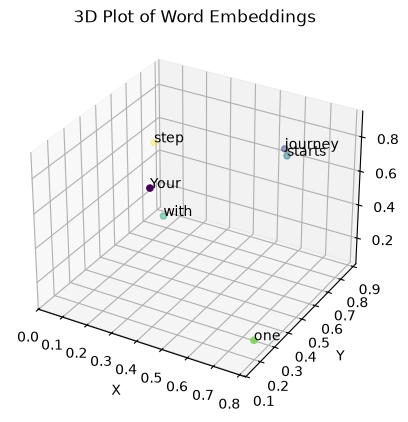

In [42]:
import matplotlib.pyplot as plt

words = ['Your', 'journey', 'starts', 'with', 'one', 'step']
points = inputs.numpy()

ax = plt.figure().add_subplot(projection='3d')
ax.scatter(*points.T, c=range(len(points)))   # .T makes the shape (3, 6), * unpacks it into x, y, z
for (x, y, z), word in zip(points, words):
    ax.text(x, y, z, word, fontsize=10)

ax.set(xlabel='X', ylabel='Y', zlabel='Z', title='3D Plot of Word Embeddings')
plt.show()


In [43]:
query = inputs[1]  # 2nd input token is the query

attn_scores_2 = torch.empty(inputs.shape[0])
for i, x_i in enumerate(inputs):
    attn_scores_2[i] = torch.dot(x_i, query) # dot product (transpose not necessary here since they are 1-dim vectors)

print(attn_scores_2)

tensor([0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865])


In [44]:
attention_weights_2 = attn_scores_2 / attn_scores_2.sum()
print(attention_weights_2)

tensor([0.1455, 0.2278, 0.2249, 0.1285, 0.1077, 0.1656])


## It is advisable to use softmax for normalization

Softmax turns the attention scores into weights that are always positive and sum to 1. Because of the exponent, larger scores get a bigger share of the weight than they would with plain sum normalization.

$$\text{softmax}(x_i) = \frac{e^{x_i}}{\sum_{j=1}^{T} e^{x_j}}$$

### Unstable (naive) softmax

Computes the formula directly. `exp()` of a large score overflows to `inf`.

In [45]:
def softmax_unstable(x: torch.Tensor) -> torch.Tensor:
    return torch.exp(x) / torch.exp(x).sum(dim=-1, keepdim=True)

attn_weights_2_unstable = softmax_unstable(attn_scores_2)
print("Attention weights:", attn_weights_2_unstable)
print("Sum:", attn_weights_2_unstable.sum())

Attention weights: tensor([0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581])
Sum: tensor(1.)


### Stable softmax

Subtract the largest score $m = \max_k w_{2k}$ before `exp()`. Every exponent is then $\le 0$, so each $e^{(\cdot)}$ lies in $(0, 1]$ and can't overflow. The $e^{-m}$ factor cancels, so the result is unchanged:

$$\alpha_{2j} = \frac{e^{w_{2j} - m}}{\sum_{k=1}^{T} e^{w_{2k} - m}}$$

In [46]:
def softmax_stable(x: torch.Tensor) -> torch.Tensor:
    exp_x = torch.exp(x - x.max(dim=-1, keepdim=True).values)
    return exp_x / exp_x.sum(dim=-1, keepdim=True)

# attn_weights_2_stable = softmax_stable(attn_scores_2)
attn_weights_2_stable = torch.softmax(attn_scores_2, dim=-1)
print("attention_weights_using_sum: ", attention_weights_2)
print("Attention weights unstable:", attn_weights_2_stable)

# torch.softmax uses the same max-subtraction trick
attn_weights_2 = torch.softmax(attn_scores_2, dim=-1)
print("torch.softmax:    ", attn_weights_2)

attention_weights_using_sum:  tensor([0.1455, 0.2278, 0.2249, 0.1285, 0.1077, 0.1656])
Attention weights unstable: tensor([0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581])
torch.softmax:     tensor([0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581])


### Why stability matters

With large scores, `exp(100)` overflows float32 (max ≈ 3.4e38), giving `inf / inf = nan` in the naive version.

In [47]:
large_scores = torch.tensor([100.0, 101.0, 102.0])
print("Naive: ", softmax_unstable(large_scores))
print("Stable:", softmax_stable(large_scores))
print("torch: ", torch.softmax(large_scores, dim=-1))

Naive:  tensor([nan, nan, nan])
Stable: tensor([0.0900, 0.2447, 0.6652])
torch:  tensor([0.0900, 0.2447, 0.6652])


## Computing the context vector

The context vector is the weighted sum of all the input vectors:

$$z^{(2)} = \sum_{j=1}^{T} \alpha_{2j}\, x^{(j)}$$

In [48]:
context_vec_2 = torch.zeros(query.shape)
for j, x_j in enumerate(inputs):
    context_vec_2 += attn_weights_2[j] * x_j
print("Loop:  ", context_vec_2)

# Same weighted sum as a single matrix-vector product
context_vec_2 = torch.matmul(attn_weights_2, inputs)
print("matmul:", context_vec_2)

Loop:   tensor([0.4419, 0.6515, 0.5683])
matmul: tensor([0.4419, 0.6515, 0.5683])


## Simplified self-attention for all inputs

Repeating the same steps for every input as the query gives the full attention weight matrix. Each row of the result is one context vector:

$$W = X X^T, \qquad A = \text{softmax}(W) \text{ applied to each row}, \qquad Z = A X$$

In [49]:
def simplified_self_attention(x: torch.Tensor) -> torch.Tensor:
    attn_scores = torch.matmul(x, x.T)                 # (T, T)
    attn_weights = torch.softmax(attn_scores, dim=-1)  # normalize each row
    return torch.matmul(attn_weights, x)               # (T, d)

context_vecs = simplified_self_attention(inputs)
print(context_vecs)
print("Row 2 matches context_vec_2:", torch.allclose(context_vecs[1], context_vec_2))

tensor([[0.4421, 0.5931, 0.5790],
        [0.4419, 0.6515, 0.5683],
        [0.4431, 0.6496, 0.5671],
        [0.4304, 0.6298, 0.5510],
        [0.4671, 0.5910, 0.5266],
        [0.4177, 0.6503, 0.5645]])
Row 2 matches context_vec_2: True


## Attention

Self-Attention is implemented by adding 3 trainable weight matrix to the 
simplified attention we discussed above.

$$ W_q, W_k, W_v $$

Each input $x^{(i)}$ is projected into a query, a key and a value vector:

$$q^{(i)} = x^{(i)} W_q, \qquad k^{(i)} = x^{(i)} W_k, \qquad v^{(i)} = x^{(i)} W_v$$

The attention scores now come from queries and keys instead of the raw inputs, and the context vector is a weighted sum of the values.

### Step by step for query 2 ("journey")

In [50]:
import torch.nn as nn

d_in = inputs.shape[1]  # input embedding size, 3
d_out = 2               # q/k/v size, kept different from d_in to make the shapes visible

torch.manual_seed(123)
W_query = nn.Parameter(torch.rand(d_in, d_out))
W_key = nn.Parameter(torch.rand(d_in, d_out))
W_value = nn.Parameter(torch.rand(d_in, d_out))

x_2 = inputs[1]
query_2 = torch.matmul(x_2, W_query)    # (d_out,)
keys = torch.matmul(inputs, W_key)      # (T, d_out)
values = torch.matmul(inputs, W_value)  # (T, d_out)
print("query_2:", query_2)
print("keys.shape:", keys.shape, "values.shape:", values.shape)

query_2: tensor([0.4306, 1.4551], grad_fn=<SqueezeBackward4>)
keys.shape: torch.Size([6, 2]) values.shape: torch.Size([6, 2])


### Scaled dot-product attention

The scores are divided by $\sqrt{d_k}$ (the key size) before softmax. Without it, dot products grow with the vector size, softmax becomes very peaked, and the gradients get very small during training.

$$\alpha_{2j} = \text{softmax}\left(\frac{q^{(2)} \cdot k^{(j)}}{\sqrt{d_k}}\right), \qquad z^{(2)} = \sum_{j=1}^{T} \alpha_{2j}\, v^{(j)}$$

In [51]:
attn_scores_2 = torch.matmul(query_2, keys.T)  # (T,)
d_k = keys.shape[-1]
attn_weights_2 = torch.softmax(attn_scores_2 / d_k**0.5, dim=-1)
context_vec_2 = torch.matmul(attn_weights_2, values)  # (d_out,)

print("Attention weights:", attn_weights_2)
print("Context vector:   ", context_vec_2)

Attention weights: tensor([0.1500, 0.2264, 0.2199, 0.1311, 0.0906, 0.1820],
       grad_fn=<SoftmaxBackward0>)
Context vector:    tensor([0.3061, 0.8210], grad_fn=<SqueezeBackward4>)


#### Why scale by $\sqrt{d_k}$?

Dividing by $\sqrt{d_k}$ stops the scores from growing with the vector size. Without it, softmax pushes almost all the weight onto one or two tokens, and training stalls.

**Why the scores grow.** A dot product $q \cdot k = \sum_{i=1}^{d_k} q_i k_i$ adds up $d_k$ terms. If each $q_i$ and $k_i$ is roughly zero-mean with variance 1, the sum has variance $d_k$, so a typical score is about $\sqrt{d_k}$ in size. Dividing by $\sqrt{d_k}$ brings the scores back to variance about 1, whatever the head size.

**What large scores do to softmax.** Because of the exponential, large differences between scores send almost all the weight to the largest one. With random $q$ and $k$ for 6 tokens:

| $d_k$ | Version | Score std | Attention weights |
|---|---|---|---|
| 2 | unscaled | 1.27 | `[0.011, 0.105, 0.537, 0.137, 0.139, 0.071]` |
| 2 | scaled | 0.90 | `[0.027, 0.132, 0.419, 0.160, 0.162, 0.101]` |
| 128 | unscaled | 7.41 | `[0.016, 0.000, 0.580, 0.000, 0.000, 0.403]` |
| 128 | scaled | 0.65 | `[0.192, 0.129, 0.263, 0.114, 0.046, 0.255]` |

At $d_k = 2$ scaling barely matters. At $d_k = 128$, a typical head size in real models, the unscaled version gives three tokens zero weight.

**Why that stalls training.** The gradient of softmax for token $j$ is proportional to its weight $\alpha_j$. Tokens with weight ≈ 0 get almost no gradient, so $W_q$ and $W_k$ get no signal to learn whether those tokens should have been attended to.

**Why the simplified version didn't scale.** It had no trainable weights, so there were no gradients to protect, and its vectors were only 3 long, so the scores stayed small. The scaling comes from the original Transformer paper, which is why this is called *scaled* dot-product attention.

### Self-attention for all inputs

With $X$ holding the inputs as rows:

$$Q = X W_q, \quad K = X W_k, \quad V = X W_v, \qquad Z = \text{softmax}\left(\frac{Q K^T}{\sqrt{d_k}}\right) V$$

Wrapping the three matrices in an `nn.Module` registers them as trainable parameters.

In [52]:
class SelfAttention(nn.Module):
    def __init__(self, d_in: int, d_out: int):
        super().__init__()
        self.W_query = nn.Parameter(torch.rand(d_in, d_out))
        self.W_key = nn.Parameter(torch.rand(d_in, d_out))
        self.W_value = nn.Parameter(torch.rand(d_in, d_out))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        attn_scores = torch.matmul(torch.matmul(x, self.W_query), torch.matmul(x, self.W_key).T)  # (T, T)
        attn_weights = torch.softmax(attn_scores / self.W_key.shape[-1]**0.5, dim=-1)
        return torch.matmul(attn_weights, torch.matmul(x, self.W_value))                         # (T, d_out)

# Same seed as above, so the module gets the same three matrices
torch.manual_seed(123)
self_attn = SelfAttention(d_in, d_out)
context_vecs = self_attn(inputs)
print(context_vecs)
print("Row 2 matches context_vec_2:", torch.allclose(context_vecs[1], context_vec_2))

tensor([[0.2996, 0.8053],
        [0.3061, 0.8210],
        [0.3058, 0.8203],
        [0.2948, 0.7939],
        [0.2927, 0.7891],
        [0.2990, 0.8040]], grad_fn=<MmBackward0>)
Row 2 matches context_vec_2: True


### Efficient self-attention

Two changes over `SelfAttention`:

1. **One projection instead of three.** $W_q$, $W_k$ and $W_v$ are stored side by side as one $(d_{in}, 3\,d_{out})$ matrix, so a single matmul produces $Q$, $K$ and $V$.
2. **Fused attention.** `F.scaled_dot_product_attention` does the scaling, softmax and weighted sum in one kernel. On NVIDIA GPUs it uses FlashAttention, which is faster and never stores the full $(T, T)$ weight matrix. On a Mac CPU or MPS it runs at about the same speed as the unfused version.

In [53]:
import torch.nn.functional as F

class SelfAttentionBest(nn.Module):
    def __init__(self, d_in: int, d_out: int):
        super().__init__()
        # W_q, W_k, W_v side by side; created in the same order as SelfAttention so the same seed gives the same values
        self.W_qkv = nn.Parameter(torch.cat([torch.rand(d_in, d_out) for _ in range(3)], dim=-1))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        queries, keys, values = torch.matmul(x, self.W_qkv).chunk(3, dim=-1)  # each (T, d_out)
        return F.scaled_dot_product_attention(queries, keys, values)          # (T, d_out)

torch.manual_seed(123)
self_attn_best = SelfAttentionBest(d_in, d_out)
context_vecs_best = self_attn_best(inputs)
print(context_vecs_best)
print("Matches SelfAttention:", torch.allclose(context_vecs_best, context_vecs, atol=1e-6))

tensor([[0.2996, 0.8053],
        [0.3061, 0.8210],
        [0.3058, 0.8203],
        [0.2948, 0.7939],
        [0.2927, 0.7891],
        [0.2990, 0.8040]], grad_fn=<MmBackward0>)
Matches SelfAttention: True
